In [1]:
%load_ext autoreload
%autoreload 2

from IPython.display import display
import os
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import matplotlib.colors as mcolors
import matplotlib.markers as mmarkers
from matplotlib.patches import Rectangle
import seaborn as sns
import scipy

from compcats.localizer import localizer
from compcats.datasets.fmri import nsd
from compcats.utils import model_utils

import main_analysis as ma
import paths

# Plot settings
import matplotlib as mpl
from matplotlib import rcParams
from matplotlib.font_manager import FontProperties
rcParams.update({
    'figure.autolayout': False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial"],
    })
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

# /System/Library/Fonts/Avenir.ttc

RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/preprint'
os.makedirs(PLOTS_DIR, exist_ok=True)

NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR
PRINCE2024_LOCALIZER_DIR = paths.PRINCE2024_LOCALIZER_DIR


pixdim[1,2,3] should be non-zero; setting 0 dims to 1


# Fig 2 (Main figure)

In [ ]:
# Settings

plot_dir = f'{PLOTS_DIR}/section2/main_figure/individual_models'
os.makedirs(plot_dir, exist_ok=True)

frois = ['FFA', 'PPA', 'EBA']

ordered_categories = ['faces', 'scenes', 'bodies', 'objects']

category_colors = {
    'faces': '#f09678',
    'scenes': '#a6d2e5',
    'bodies': '#a7d6a1',
    'objects': '#808080',
}

prefcat_shade = '#E6E6E6' # light gray for preferred category shading

ordered_colors = [category_colors[cat] for cat in ordered_categories]

MODEL_PLOTTING_NAMES = {
    # # AlexNets
    'alexnetimagenet1kv1': 'AlexNet ImageNet-1K',
    'alexnetipclref01': 'AlexNet IPCL',
    'alexnetbarlowtwins': 'AlexNet Barlow-Twins',
    # # VGGs
    'vgg16imagenet1kv1': 'VGG-16 ImageNet-1K',
    # # ResNet-18s
    'resnet18imagenet1kv1': 'ResNet-18 ImageNet-1K',
    'resnet18tdannsupervisedlw10': 'ResNet-18 TDANN-Supervised',
    'resnet18tdannsimclrlw1': 'ResNet-18 TDANN-SimCLR',
    # # ResNet-50s
    'resnet50imagenet1kv2': 'ResNet-50 ImageNet-1K',
    'resnet50openaiclip': 'ResNet-50 CLIP',
    'resnet50simclr': 'ResNet-50 SimCLR',
    'resnet50robustl2eps3': 'ResNet-50 Robust',
    'resnet50sin': 'ResNet-50 Shape-Biased',
    'resnet50ecoset': 'ResNet-50 EcoSet',
    'resnet50faceobfuscation': 'ResNet-50 Face-Deprived',
    'resnet50toponettau30': 'ResNet-50 TopoNet',
    'resnet50cesslbarlowtop': 'ResNet-50 CE-SSL',
    'resnet50blurstrong': 'ResNet-50 Strong-Blur',
    # # ResNet-101s
    'resnet101imagenet1kv1': 'ResNet-101 ImageNet-1K',
    'resnet101openaiclip': 'ResNet-101 CLIP',
    # # # BagNets
    'bagnet33': 'BagNet-33 ImageNet-1K',
    # # # CORNets
    'cornets': 'CORNet-S',
    'cornetz': 'CORNet-Z',
    # # # ConvNeXt
    'convnexttinyimagenet1kv1': 'ConvNeXt-T ImageNet-1K',
    # # # ViTs
    # # # ViT-B/32
    'vitb32imagenet1kv1': 'ViT-B/32 ImageNet-1K',
    'vitb32openaiclip': 'ViT-B/32 CLIP',
    'vitb32dreamsimopenclip': 'ViT-B/32 DreamSim',
    # # # ViT-B/16
    'vitb16imagenet21k': 'ViT-B/16 ImageNet-21K',
    'vitb16openaiclip': 'ViT-B/16 CLIP',
    'vitb16siglip2res224': 'ViT-B/16 SigLIP2',
    'vitb16eva028bs8bb131k': 'ViT-B/16 EVA-02',
    'vitb16synclr': 'ViT-B/16 SynCLR',
    # # # ViT-B/14
    'vitb14dinov2': 'ViT-B/14 DINOv2',
    'vitb14dinov2reg': 'ViT-B/14 DINOv2-Reg',
    # # # ViT-L/14
    'vitl14openaiclip': 'ViT-L/14 CLIP',
    'vitl14kosmos2': 'ViT-L/14 Kosmos-2',
    # Random models
    'alexnetrandom1': 'AlexNet Random',
    'alexnetrandom2': 'AlexNet Random',
    'alexnetrandom3': 'AlexNet Random',
    'alexnetrandom4': 'AlexNet Random',
    'alexnetrandom5': 'AlexNet Random',
    'resnet18random1': 'ResNet-18 Random',
    'resnet18random2': 'ResNet-18 Random',
    'resnet18random3': 'ResNet-18 Random',
    'resnet18random4': 'ResNet-18 Random',
    'resnet18random5': 'ResNet-18 Random',
    'resnet50random1': 'ResNet-50 Random',
    'resnet50random2': 'ResNet-50 Random',
    'resnet50random3': 'ResNet-50 Random',
    'resnet50random4': 'ResNet-50 Random',
    'resnet50random5': 'ResNet-50 Random',
    'vitb32random1': 'ViT-B/32 Random',
    'vitb32random2': 'ViT-B/32 Random',
    'vitb32random3': 'ViT-B/32 Random',
    'vitb32random4': 'ViT-B/32 Random',
    'vitb32random5': 'ViT-B/32 Random',
}

Processing model: resnet50imagenet1kv2, froi: FFA
Processing model: resnet50imagenet1kv2, froi: PPA
[-2.3266194 -1.9007112 -1.7367597 -2.0332386 -1.7105689 -1.9185417
 -1.5927969 -1.6295705 -1.6297503 -1.1637368 -1.9965304 -1.2664071
 -1.4400228 -1.8750371 -1.9698099 -1.4372358 -2.1568613 -1.8211149
 -1.6835649 -1.8571621 -1.7003253 -1.3926057 -1.5796479 -1.7397405
 -1.3450842 -1.8092638 -1.7997164 -1.9725623 -1.6802747 -1.472594
 -1.2701519 -1.4705828 -1.2130022 -1.889731  -1.6697367 -1.965241
 -1.6989579 -1.9634267 -1.7799706 -2.171131  -1.6254394 -2.2964935
 -1.6953709 -1.3857073 -1.417528  -0.8919779 -1.9665515 -1.4462724
 -1.7028826 -1.2075105 -1.2615457 -1.5632082 -1.4420865 -1.867162
 -1.8802304 -1.6891565 -1.61789   -1.7951003 -2.1766267 -1.6278255
 -1.8628964 -1.3936301 -1.4560149 -1.5560535 -1.6115427 -1.6161813
 -1.2353057 -1.7249655 -1.364022  -1.5823182 -1.2878462 -1.347815
 -1.2213805 -1.9028286 -1.3360595 -0.9974308 -1.7027481 -1.8415458
 -1.5130917 -1.957958 ] -2.326619

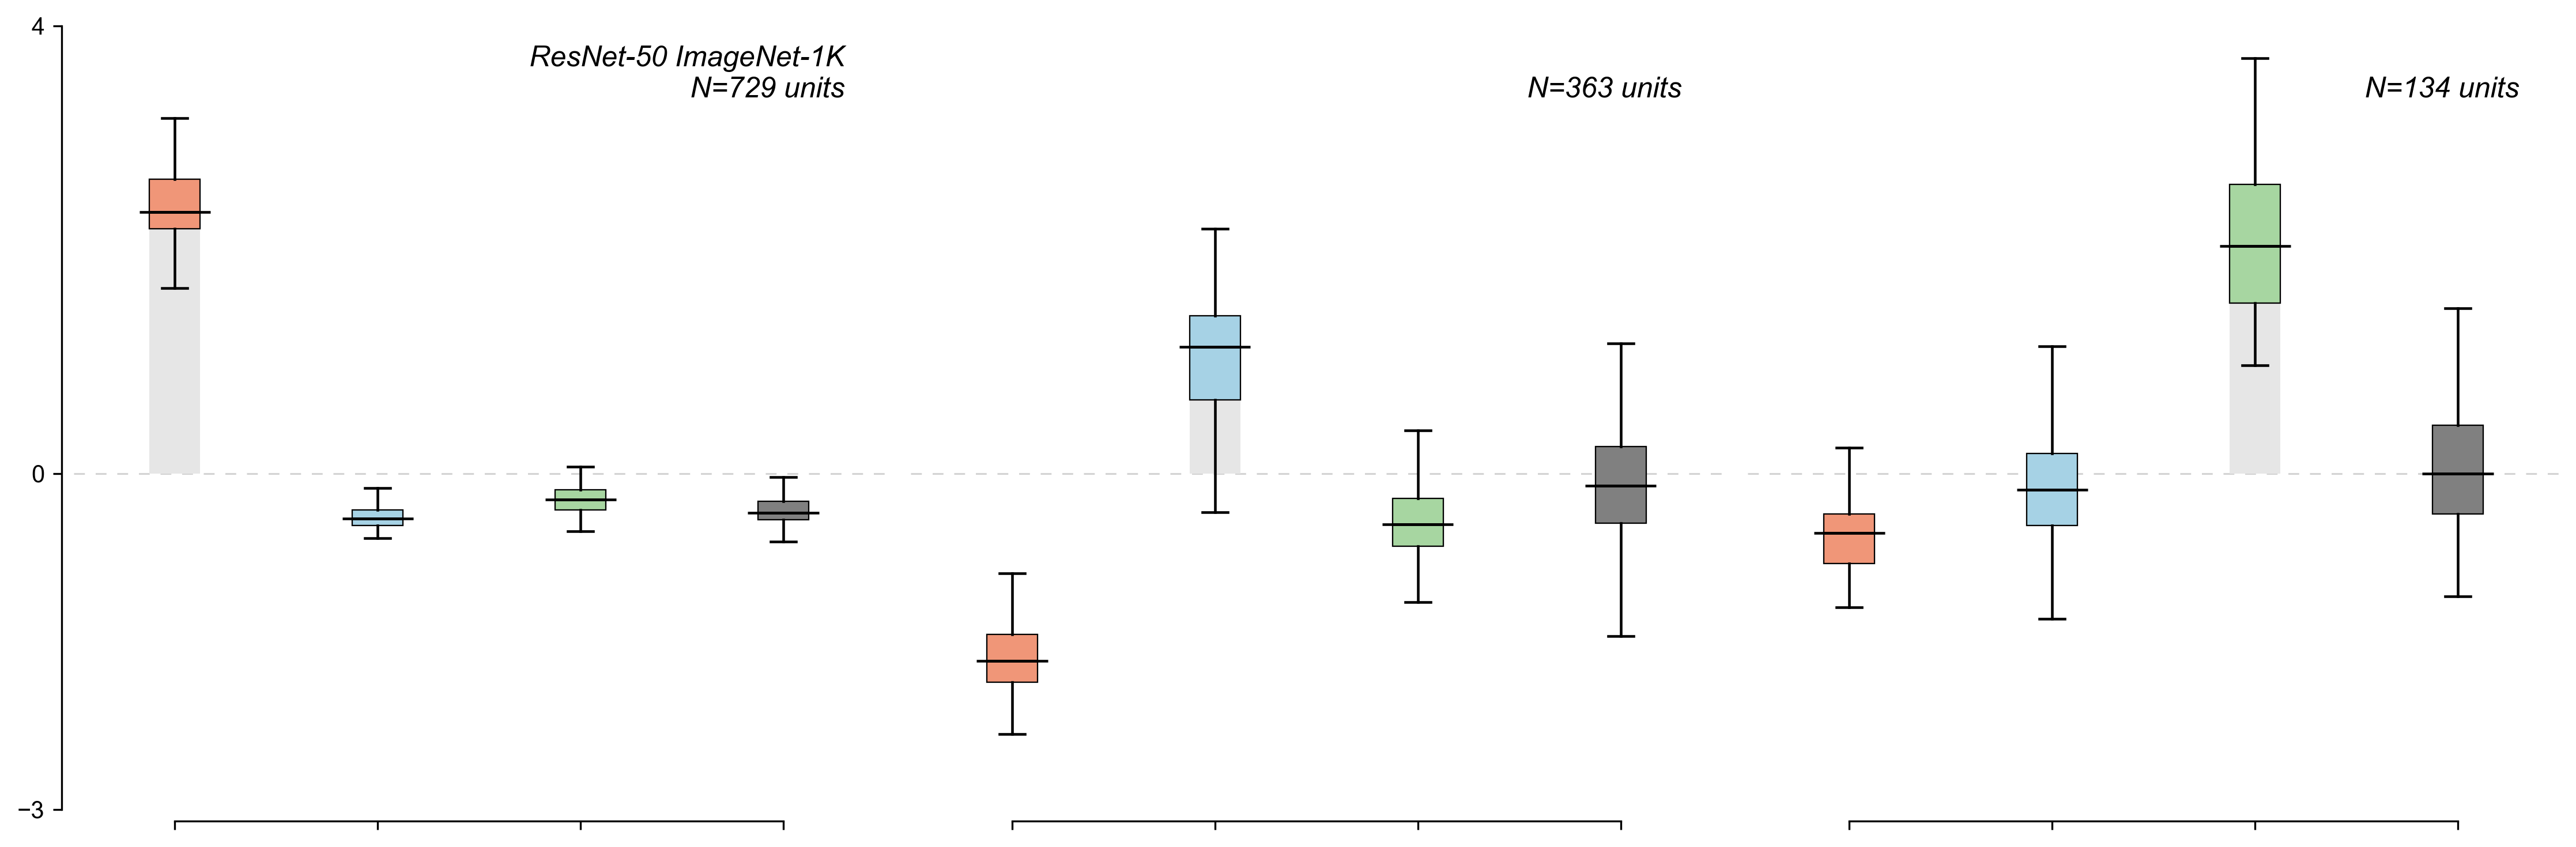

Processing model: vitb16siglip2res224, froi: FFA
Processing model: vitb16siglip2res224, froi: PPA
Processing model: vitb16siglip2res224, froi: EBA


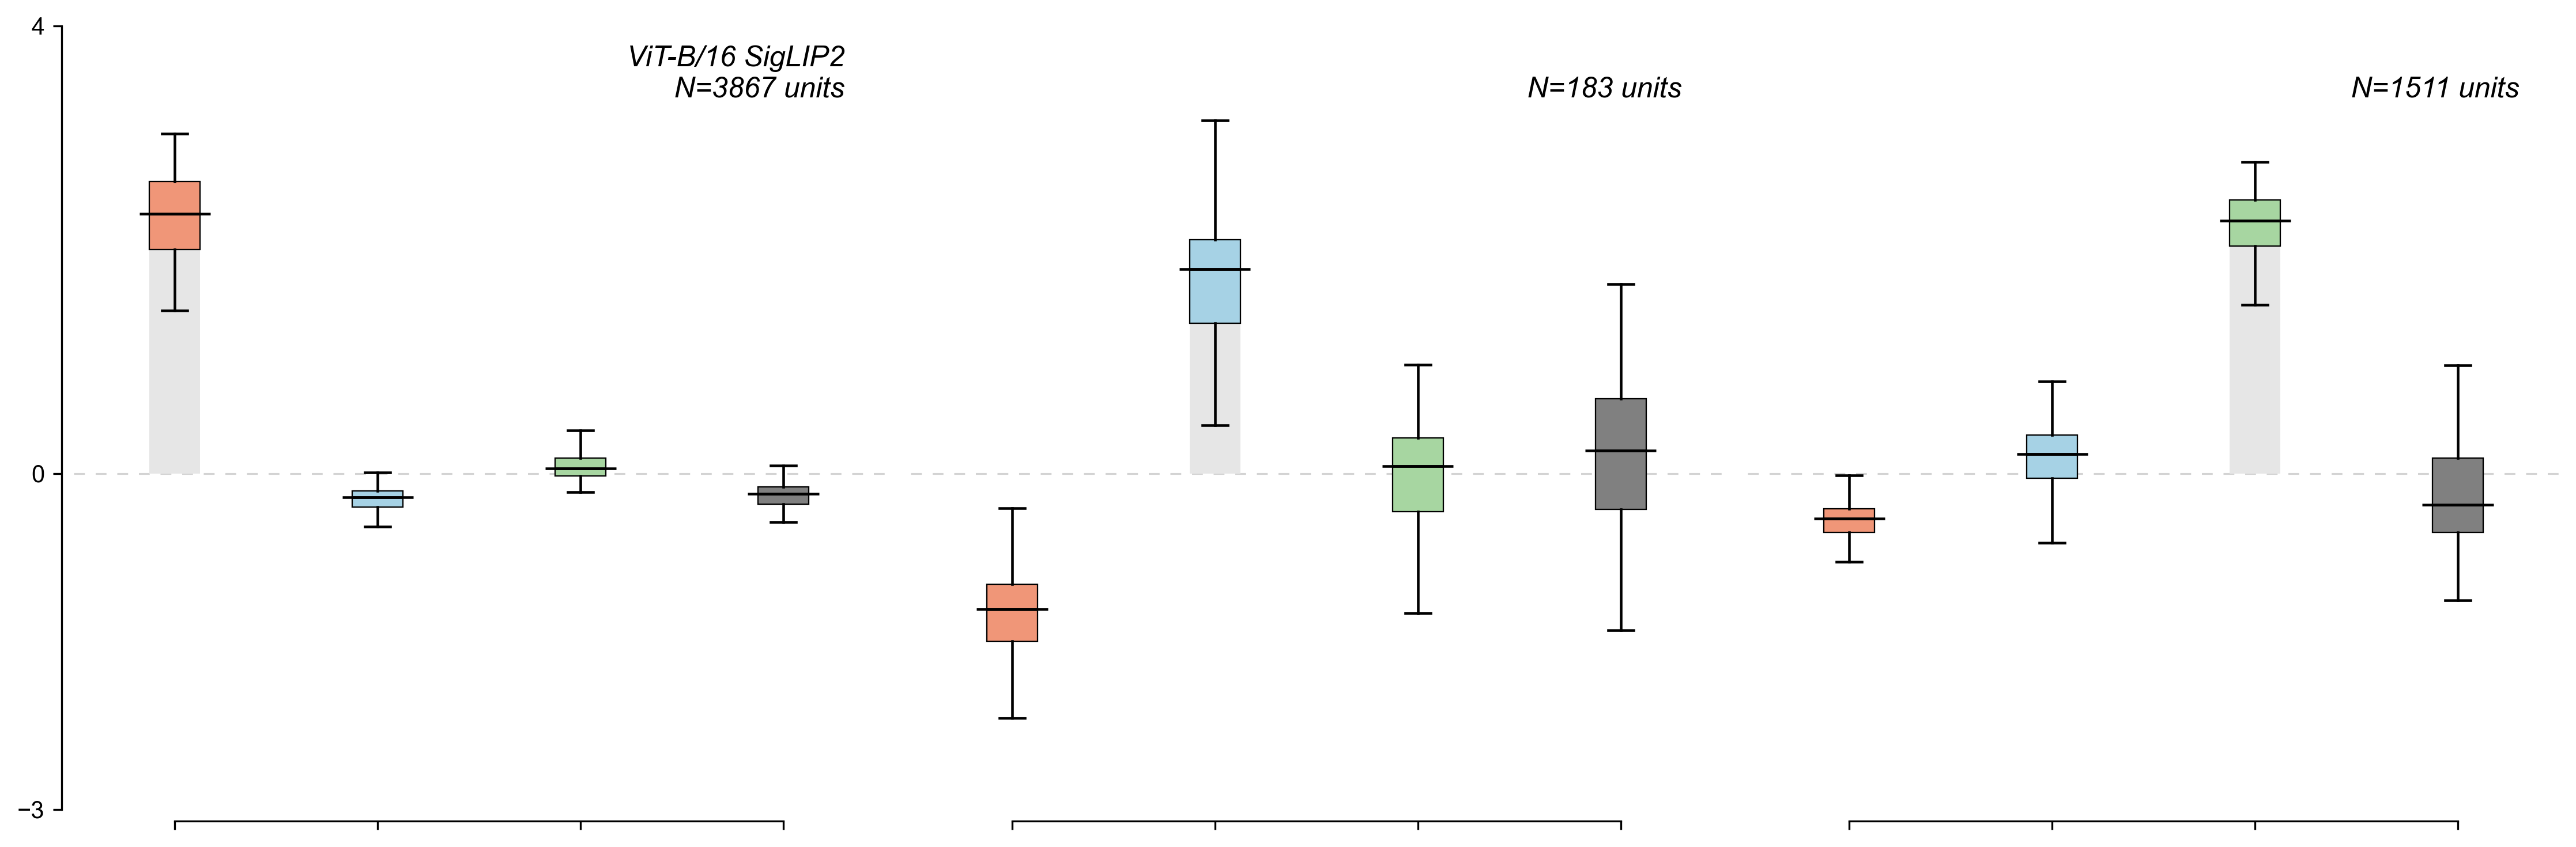

Initialized alexnetrandom5 with seed = 5
Processing model: alexnetrandom5, froi: FFA
Initialized alexnetrandom5 with seed = 5
Processing model: alexnetrandom5, froi: PPA
Initialized alexnetrandom5 with seed = 5
Processing model: alexnetrandom5, froi: EBA


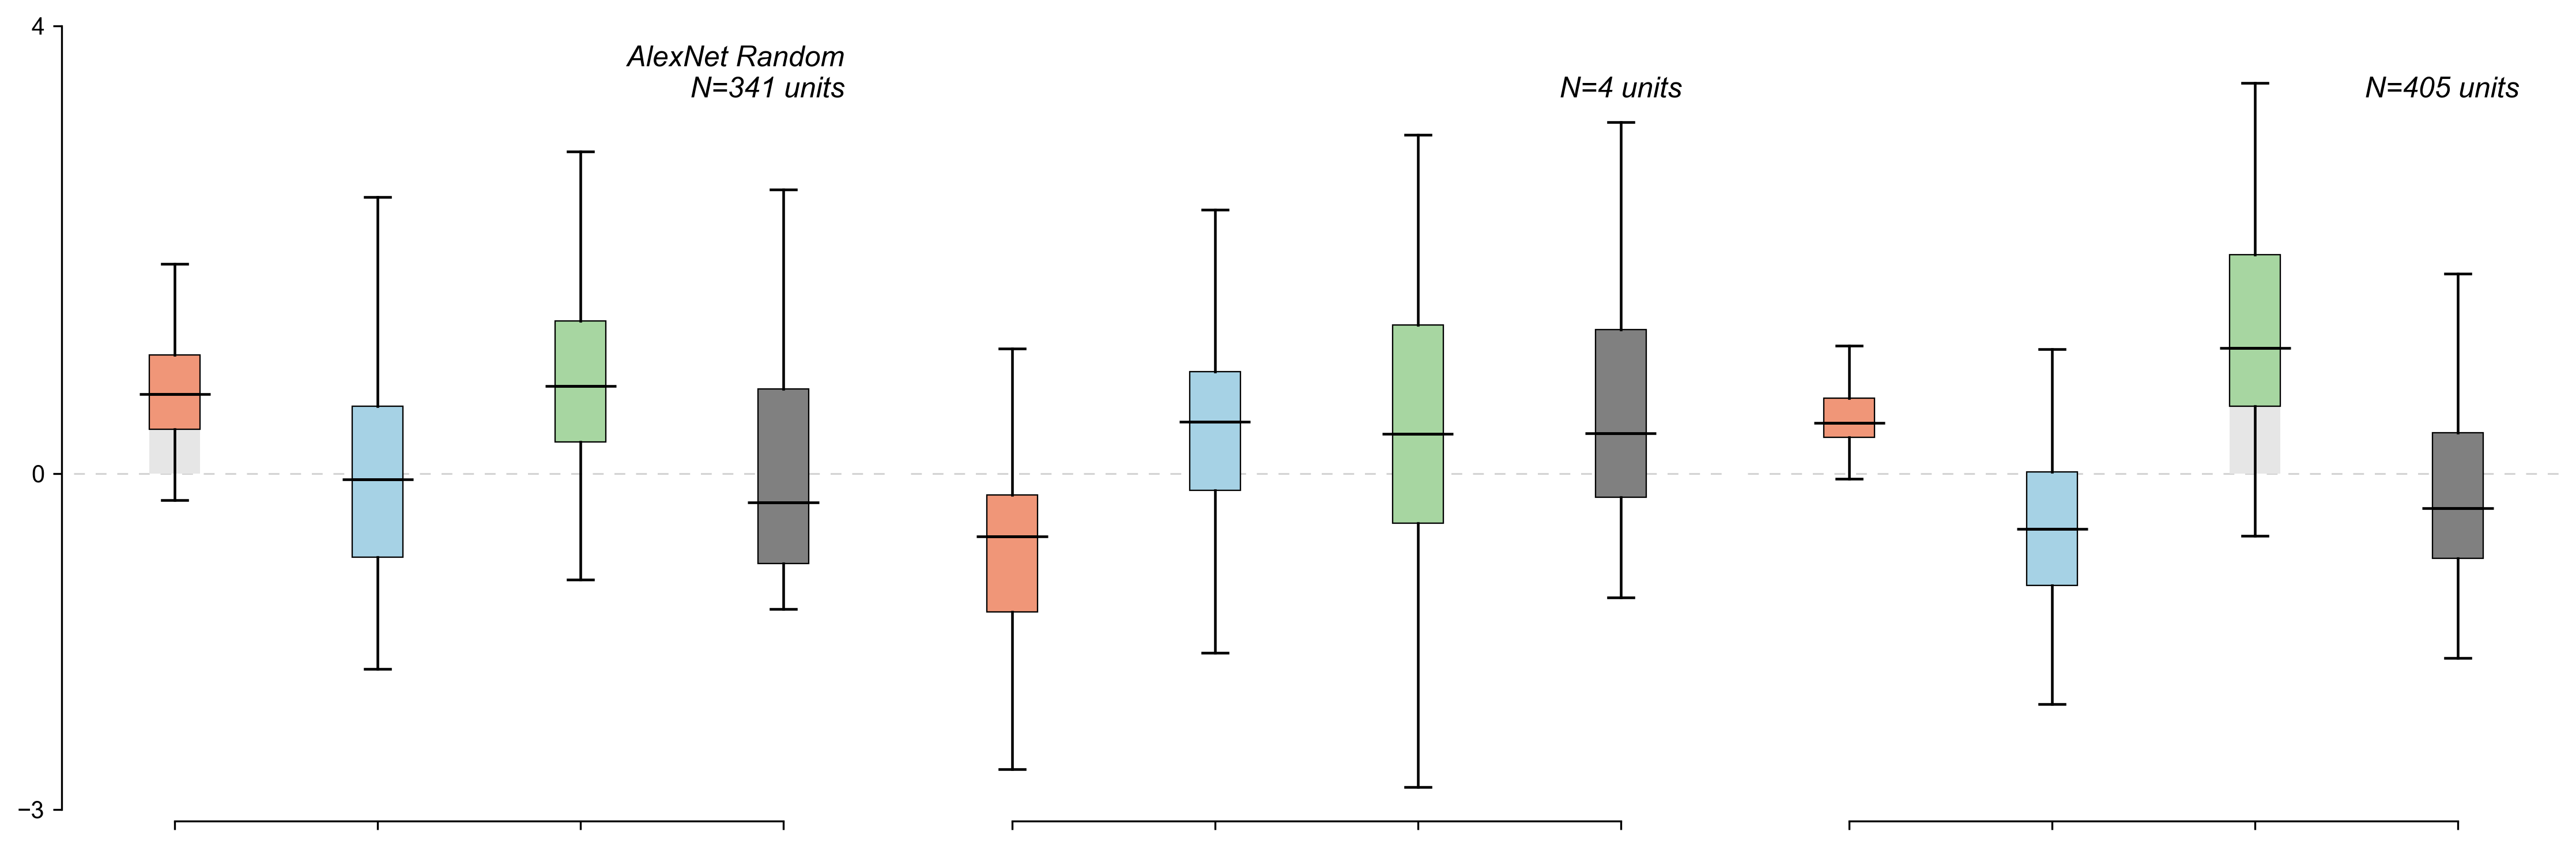

In [23]:
savefig = False
model_names = [
    'resnet50imagenet1kv2',
    'vitb16siglip2res224',
    'alexnetrandom5',
]

for model_name in model_names:
    tthreshold = 3 if 'random' in model_name else 7
    model_localizer = 'grillspector'
    model_localizer_dir = GRILLSPECTOR_LOCALIZER_DIR
    indepedent_localizer = 'prince2024'
    indepedent_localizer_dir = PRINCE2024_LOCALIZER_DIR

    # Set up the plot
    # plt.figure(figsize=(5, 5), dpi=300)
    # 1 row, 3 columns
    fig, ax = plt.subplots(1, 3, figsize=(15, 5), dpi=300)

    for fidx, froi in enumerate(frois):
        ax_current = ax[fidx]
        pref_category = None
        if froi == 'FFA':
            pref_category = 'faces'
        elif froi == 'PPA':
            pref_category = 'scenes'
        elif froi == 'EBA':
            pref_category = 'bodies'
        model = ma.get_model(model_name)
        model.eval()
        print(f'Processing model: {model.name}, froi: {froi}')
        # Get number of units localized in the froi
        froi_mask = localizer.get_froi_mask(
            model_localizer_dir, model_localizer, MODELS_DIR,
            model, ma.get_froi_models_layers(froi, froi)[model.name],
            froi, tthreshold
        )
        num_units = froi_mask.sum().item()
        # FBSO
        independent_acts = model_utils.get_dataset_activations(
            MODELS_DIR, indepedent_localizer_dir, \
            model, ma.get_froi_models_layers(froi, froi)[model.name],
            dataset='localizer', localizer_type=indepedent_localizer, \
            froi=froi, tthreshold=tthreshold, \
            froi_localizer=model_localizer, froi_localizer_dir=model_localizer_dir
        )
        independent_acts_univariate = {k: v.mean(axis=-1) for k, v in independent_acts.items()}

        # Prepare data for plotting with z-scoring
        categories = list(independent_acts_univariate.keys())

        # Reorder categories and rename 'places' to 'scenes'
        # category_mapping = {'places': 'scenes', 'scrambledobjects': 'scrambled objects'}
        # display_names = [category_mapping.get(cat, cat) for cat in ordered_categories]

        # Get all activations and compute overall mean and std for z-scoring
        all_vals = torch.cat([independent_acts_univariate[cat] for cat in categories])
        overall_mean = all_vals.mean().cpu().numpy()
        overall_std = all_vals.std().cpu().numpy()

        # Compute z-scored medians and SEMs for the ordered categories
        # z_medians = [torch.median(independent_acts_univariate[cat]).cpu().numpy() for cat in ordered_categories]
        # z_sems = [torch.std(independent_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(independent_acts_univariate[cat])) for cat in ordered_categories]
        # z_sems = None
        # z_medians = [(torch.median(independent_acts_univariate[cat]).cpu().numpy() - overall_mean) / overall_std for cat in ordered_categories]
        # z_sems = [(torch.std(independent_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(independent_acts_univariate[cat]))) / overall_std for cat in ordered_categories]
        z_means = [(torch.mean(independent_acts_univariate[cat]).cpu().numpy() - overall_mean) / overall_std for cat in ordered_categories]
        z_sems = [(torch.std(independent_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(independent_acts_univariate[cat]))) for cat in ordered_categories]

        # Add horizontal line at z=0
        ax_current.axhline(
            y=0, color='lightgray', alpha=1, linewidth=0.75, zorder=0,
            linestyle=(0, (6, 6))  # (offset, (dash_length, gap_length))
        )
        # bar_positions = np.arange(len(ordered_categories))
        # # bars = plt.bar(bar_positions, z_medians, yerr=z_sems, capsize=3, 
        # #                color=['coral' if cat == pref_category else 'skyblue' for cat in ordered_categories])
        # # bars = plt.bar(bar_positions, z_medians, yerr=z_sems, capsize=0, color='gray', error_kw={'linewidth': 1})
        # bars = plt.bar(bar_positions, z_means, yerr=z_sems, capsize=0, color=ordered_colors, error_kw={'linewidth': 1})
        # Box plot
        # Box plot data preparation
        box_data = []
        for cat in ordered_categories:
            # Z-score the data for each category
            cat_data = (independent_acts_univariate[cat].cpu().numpy() - overall_mean) / overall_std
            if model_name == 'resnet50imagenet1kv2' and froi=='PPA' and cat == 'faces':
                print(cat_data, np.min(cat_data), np.max(cat_data), np.median(cat_data))
                x = cat_data
                q1 = np.percentile(x, 25)
                q3 = np.percentile(x, 75)
                iqr = q3 - q1

                lower_bound = q1 - 1.5 * iqr
                upper_bound = q3 + 1.5 * iqr

                lower_whisker = x[x >= lower_bound].min()
                upper_whisker = x[x <= upper_bound].max()

                outliers = x[(x < lower_bound) | (x > upper_bound)]

                print("Q1:", q1)
                print("Q3:", q3)
                print("Lower whisker:", lower_whisker)
                print("Upper whisker:", upper_whisker)
                print("Outliers:", outliers)
            box_data.append(cat_data)
        
        # Store preferred category index and median
        pref_cat_idx = ordered_categories.index(pref_category)
        pref_cat_median = np.median(box_data[pref_cat_idx])
        
        # Create the box plot
        linewidth = 0.55 # 0.75
        bar_positions = np.arange(len(ordered_categories))
        barwidth = 0.25 # 0.35
        boxes = ax_current.boxplot(
                    box_data, positions=bar_positions, patch_artist=True, 
                    widths=barwidth, showfliers=False,
                    boxprops={'color': 'black', 'linewidth': linewidth},
                    whiskerprops=dict(linewidth=linewidth*2),
                    capprops=dict(linewidth=linewidth*2),
                    medianprops={'color': 'black', 'linewidth': linewidth*2},
                    flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
                )
        for i, data in enumerate(box_data):
            med = np.median(data)
            # Manually draw a longer median line
            x = bar_positions[i]  # X-position of the boxplot
            ax_current.plot(
                [x - 0.175, x + 0.175], [med, med], color='black', linewidth=linewidth*2, solid_capstyle='butt'
            )
        
        # Color the boxes according to category colors
        for box, color, cat in zip(boxes['boxes'], ordered_colors, ordered_categories):
            box.set(facecolor=color)
            # if cat == pref_category:
            #     box.set(linewidth=1.5, edgecolor='black')
            # else:
            #     box.set(linewidth=1, edgecolor='gray')

        # Add model name and num units to top right corner
        nunits_prefix = ''
        if fidx == 0:
            nunits_prefix = f'{MODEL_PLOTTING_NAMES[model.name]}'
        ax_current.text(
            0.95, 0.975,
            f'{nunits_prefix}\nN={num_units} units', 
            transform=ax_current.transAxes, fontsize=12, ha='right', va='top', fontstyle='italic'
        )

        # Add preferred category shading
        if pref_cat_median > 0:
            y_min = 0
            y_max = pref_cat_median
        else:
            y_min = pref_cat_median
            y_max = 0
        rect = Rectangle(
            (pref_cat_idx - barwidth/2, y_min),  # bottom-left corner
            barwidth,                         # width
            y_max - y_min,                     # height
            facecolor=prefcat_shade,                   # light gray
            edgecolor='none',
            zorder=0                           # behind everything
        )
        ax_current.add_patch(rect)

        # Add labels and title
        # Remove top and right spines
        ax_current.spines['top'].set_visible(False)
        ax_current.spines['right'].set_visible(False)
        ax_current.spines['left'].set_position(('outward', 5))
        ax_current.spines['bottom'].set_position(('outward', 5))
        # plt.xlabel('Categories', fontsize=12)
        # plt.ylabel('Z-scored Unit-averaged Activations', fontsize=12)
        # plt.yticks([-1.5, -0.75, 0, 0.75, 1.5, 2.25])
        ax_current.set_yticks([-3, 0, 4])
        # plt.ylim(-1.5, 2.325)
        # plt.ylim(-2, 4.5)
        ax_current.set_ylim(-3, 4)
        # plt.tick_params(axis='y', labelleft=False)
        # plt.gca().spines['left'].set_bounds(-1.5, 2.25)
        # plt.gca().spines['left'].set_bounds(-2, 4)
        ax_current.spines['left'].set_bounds(-3, 4)
        # plt.yticks([0, 1], [0, 1], fontsize=12)
        ax_current.set_xticks(bar_positions)
        ax_current.set_xticklabels([])
        ax_current.spines['bottom'].set_bounds(np.arange(len(ordered_categories))[0], np.arange(len(ordered_categories))[-1])
        if fidx > 0:
            # Hide y-axis
            ax_current.yaxis.set_visible(False)
            # Stop showing spine
            ax_current.spines['left'].set_visible(False)
    plt.tight_layout()

    # plt.savefig(f'{plot_dir}/model_localization_contrast_konkle_nozscore.pdf', dpi=300, bbox_inches='tight', transparent=True)
    # plt.savefig(f'{plot_dir}/rn18imgnet_localization_contrast_konkle_zscore.png', dpi=300, bbox_inches='tight', transparent=True)
    if savefig:
        plt.savefig(f'{plot_dir}/fig2_{model_name}_localizer_{model_localizer}_validate_{indepedent_localizer}_zscore.pdf', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    plt.close()

# Fig. S1 (Supplementary figure)

In [3]:
# Settings

plot_dir = f'{PLOTS_DIR}/section2/supplementary_figures'
os.makedirs(plot_dir, exist_ok=True)

frois = ['EBA', 'PPA', 'FFA']

ordered_categories = ['faces', 'scenes', 'bodies', 'objects']

category_colors = {
    'faces': '#f09678',
    'scenes': '#a6d2e5',
    'bodies': '#a7d6a1',
    'objects': '#808080',
}

prefcat_shade = '#E6E6E6' # light gray for preferred category shading

ordered_colors = [category_colors[cat] for cat in ordered_categories]

# Skipping the best model (ViT-B/16 SigLIP2)
ORDERED_MODELS = {
    'resnet50openaiclip': 'ResNet-50 CLIP',
    'convnexttinyimagenet1kv1': 'ConvNeXt-Tiny ImageNet-1K',
    'resnet101openaiclip': 'ResNet-101 CLIP',
    'vitb14dinov2reg': 'ViT-B/14 DINOv2-Registers',
    'resnet50simclr': 'ResNet-50 SimCLR',
    'resnet50toponettau30': 'ResNet-50 TopoNet',
    'cornets': 'CORNet-S',
    'resnet101imagenet1kv1': 'ResNet-101 ImageNet-1K',
    'vitb14dinov2': 'ViT-B/14 DINOv2',
    'resnet50cesslbarlowtop': 'ResNet-50 CE-SSL',
    'resnet18imagenet1kv1': 'ResNet-18 ImageNet-1K',
    'resnet50imagenet1kv2': 'ResNet-50 ImageNet-1K',
    'resnet50faceobfuscation': 'ResNet-50 Face-Obfuscated',
    'vitb16eva028bs8bb131k': 'ViT-B/16 EVA-02',
    'resnet50ecoset': 'ResNet-50 EcoSet',
    'vitl14kosmos2': 'ViT-L/14 KOSMOS-2',
    'vitb16synclr': 'ViT-B/16 SynCLR',
    'resnet18tdannsimclrlw1': 'ResNet-18 TDANN-SimCLR',
    'vgg16imagenet1kv1': 'VGG-16 ImageNet-1K',
    'vitb32openaiclip': 'ViT-B/32 CLIP',
    'vitb16openaiclip': 'ViT-B/16 CLIP',
    'vitl14openaiclip': 'ViT-L/14 CLIP',
    'resnet50robustl2eps3': 'ResNet-50 Robust',
    'vitb32dreamsimopenclip': 'ViT-B/32 DreamSim',
    'resnet50blurstrong': 'ResNet-50 Blur-Trained',
    'resnet50sin': 'ResNet-50 Shape-Trained',
    'bagnet33': 'BagNet-33 ImageNet-1K',
    'vitb32imagenet1kv1': 'ViT-B/32 ImageNet-1K',
    'alexnetimagenet1kv1': 'AlexNet ImageNet-1K',
    'alexnetbarlowtwins': 'AlexNet BarlowTwins',
    'vitb16imagenet21k': 'ViT-B/16 ImageNet-21K',
    'resnet18tdannsupervisedlw10': 'ResNet-18 TDANN-Supervised',
    'cornetz': 'CORNet-Z',
    'alexnetipclref01': 'AlexNet IPCL',
}


tthreshold = 7
model_localizer = 'grillspector'
model_localizer_dir = GRILLSPECTOR_LOCALIZER_DIR
indepedent_localizer = 'prince2024'
indepedent_localizer_dir = PRINCE2024_LOCALIZER_DIR

In [30]:
midx = 1
ncols = 17
n_models = len(ORDERED_MODELS)
nrows = len(frois) * (n_models//ncols)

row_idx = (midx//ncols)+(fidx)
print(f'midx: {midx}, row_idx: {row_idx}, col_idx: {midx%ncols}')

midx: 1, row_idx: 2, col_idx: 1


EBA. resnet50openaiclip: midx: 0, row_idx: 0, col_idx: 0
EBA. convnexttinyimagenet1kv1: midx: 1, row_idx: 0, col_idx: 1
EBA. resnet101openaiclip: midx: 2, row_idx: 0, col_idx: 2
EBA. vitb14dinov2reg: midx: 3, row_idx: 0, col_idx: 3


Using cache found in /Users/adipani3/.cache/torch/hub/facebookresearch_dinov2_main


EBA. resnet50simclr: midx: 4, row_idx: 0, col_idx: 4
/Users/adipani3/.cache/torch/checkpoints/1a6IO4xhWy8cdyAuWv0BxSONz7lMcKbZE.pth.tar
EBA. resnet50toponettau30: midx: 5, row_idx: 0, col_idx: 5


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/torch/amp/grad_scaler.py:136: UserWarning: torch.cuda.amp.GradScaler is enabled, but CUDA is not available.  Disabling.
  warnings.warn(
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


PPA. resnet50openaiclip: midx: 0, row_idx: 3, col_idx: 0
PPA. convnexttinyimagenet1kv1: midx: 1, row_idx: 3, col_idx: 1
PPA. resnet101openaiclip: midx: 2, row_idx: 3, col_idx: 2
PPA. vitb14dinov2reg: midx: 3, row_idx: 3, col_idx: 3


Using cache found in /Users/adipani3/.cache/torch/hub/facebookresearch_dinov2_main


PPA. resnet50simclr: midx: 4, row_idx: 3, col_idx: 4
/Users/adipani3/.cache/torch/checkpoints/1a6IO4xhWy8cdyAuWv0BxSONz7lMcKbZE.pth.tar
PPA. resnet50toponettau30: midx: 5, row_idx: 3, col_idx: 5


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/torch/amp/grad_scaler.py:136: UserWarning: torch.cuda.amp.GradScaler is enabled, but CUDA is not available.  Disabling.
  warnings.warn(
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


FFA. resnet50openaiclip: midx: 0, row_idx: 6, col_idx: 0


IndexError: index 6 is out of bounds for axis 0 with size 6

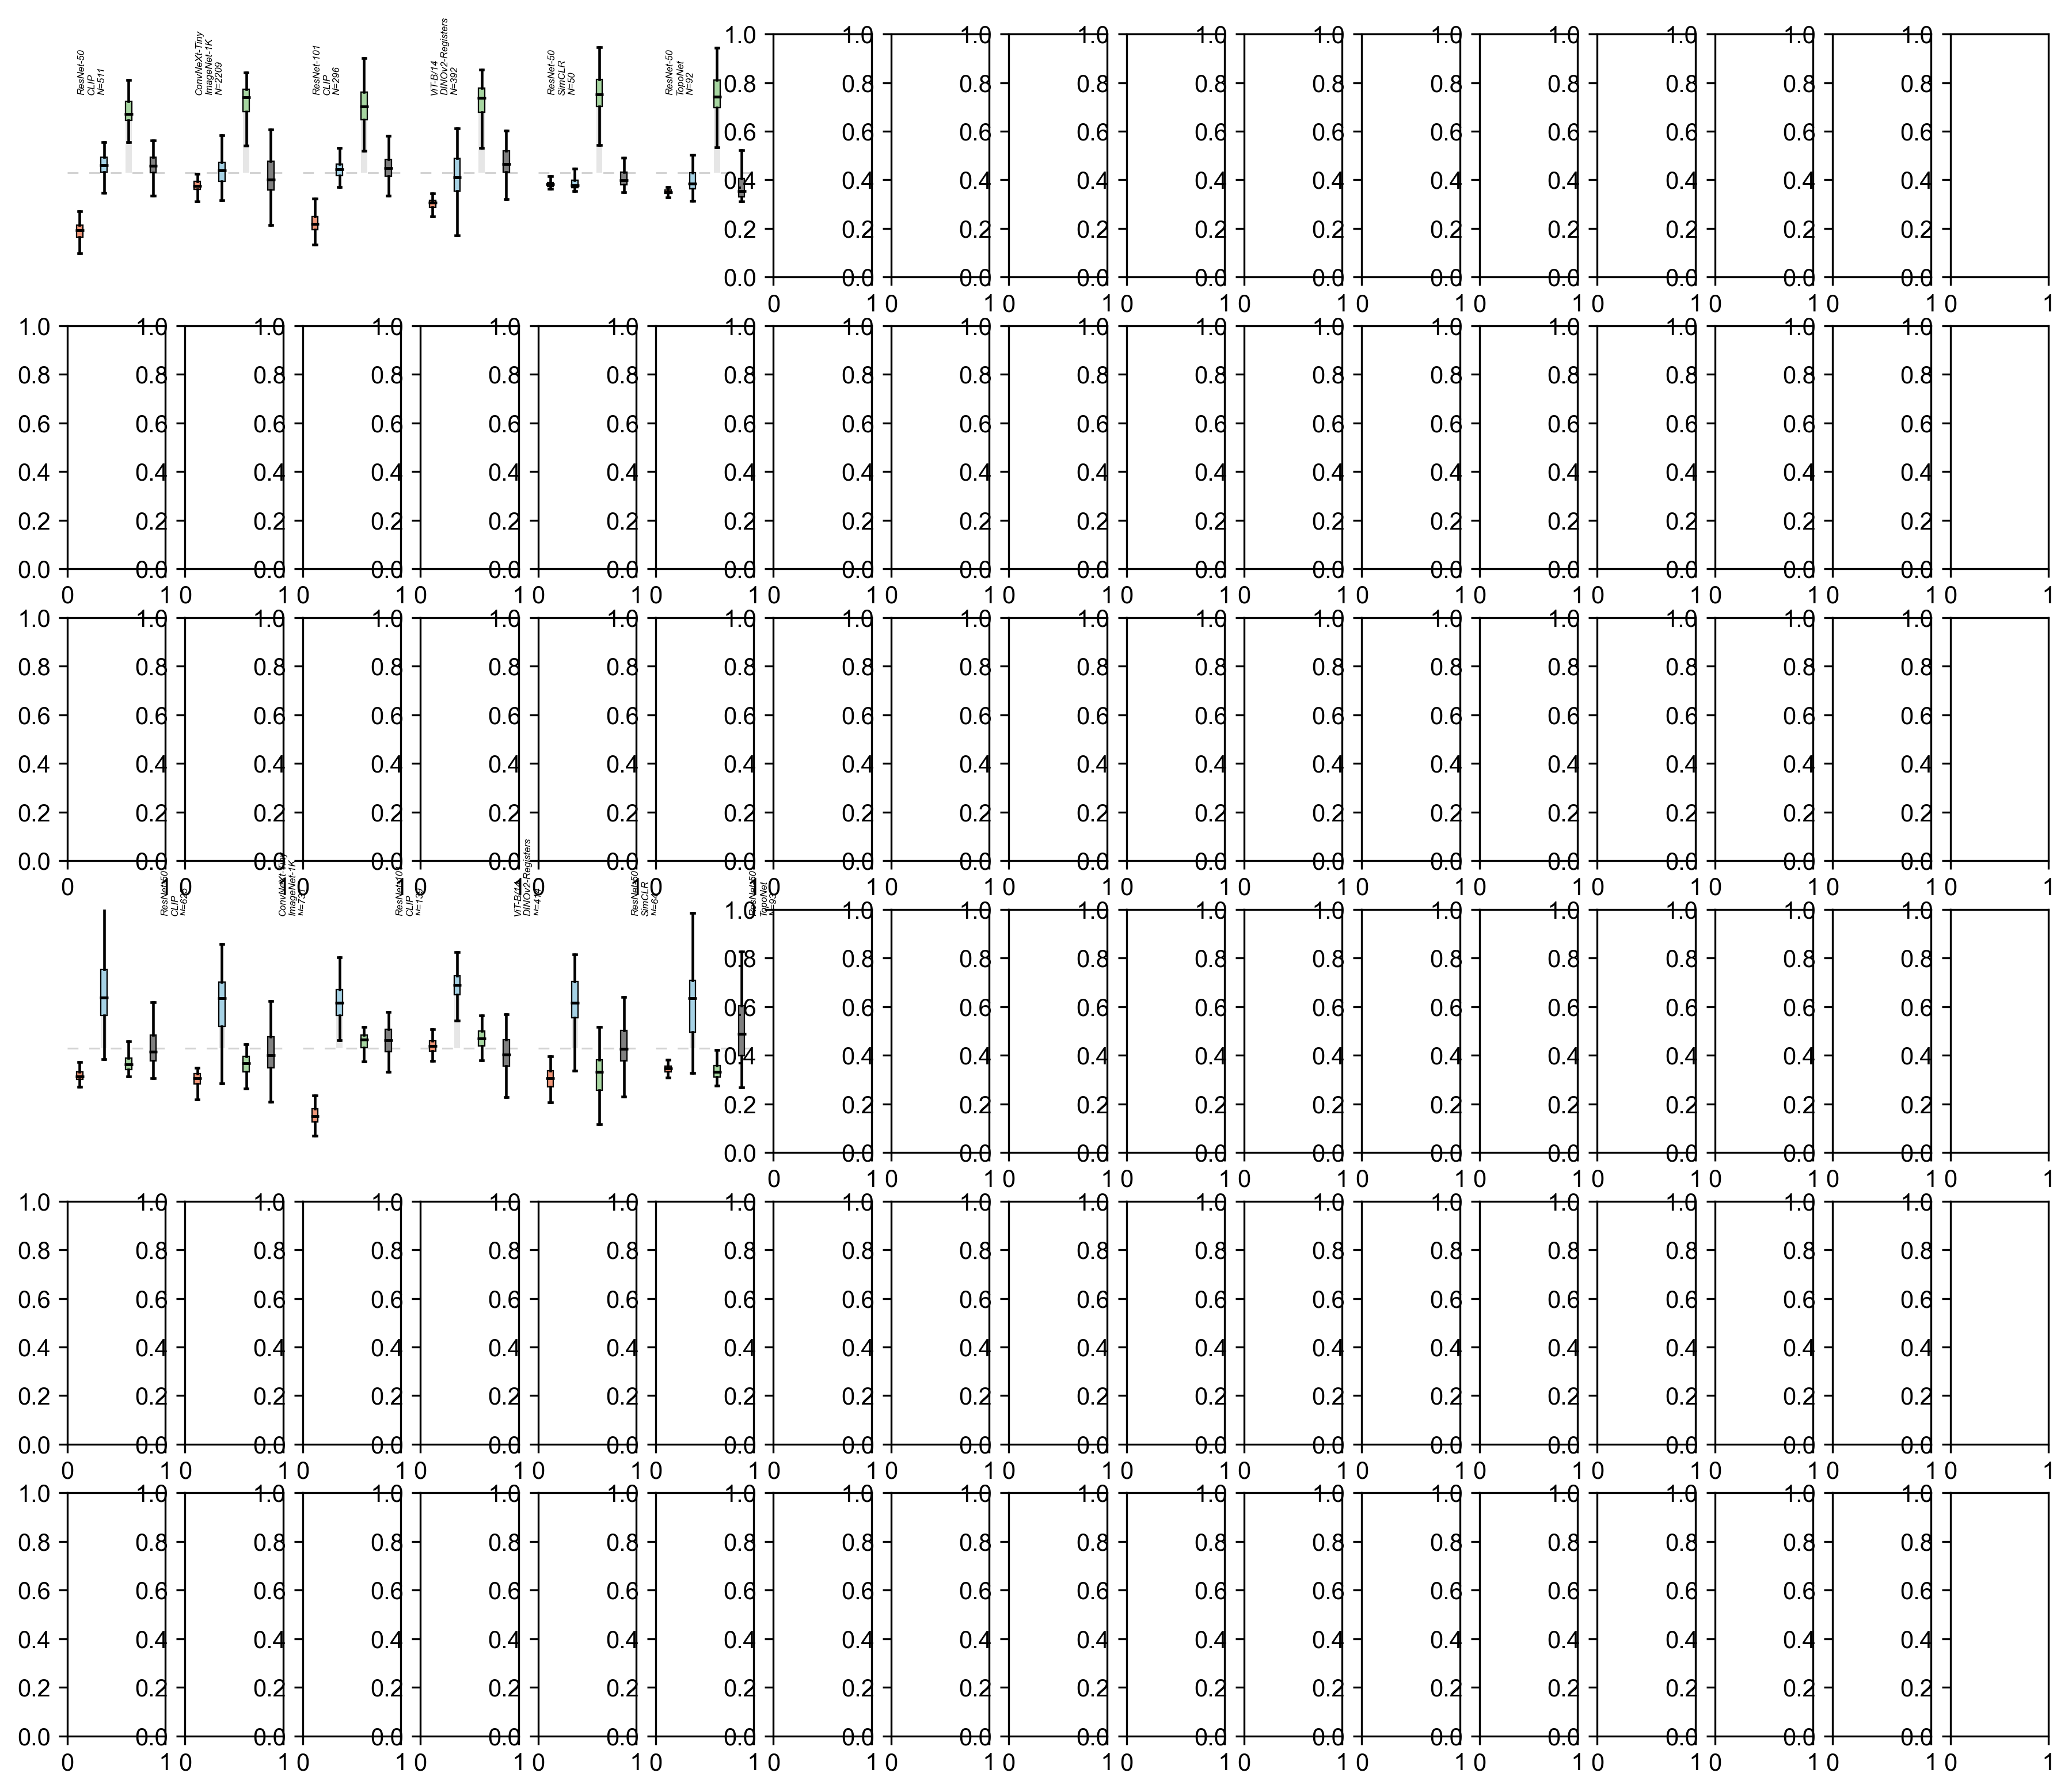

In [7]:
savefig = False
model_names = ORDERED_MODELS.keys()

froi_yticks = {
    'FFA': [-3, 0, 4],
    'PPA': [-3, 0, 4],
    'EBA': [-3, 0, 4],
}
froi_text_locs = {
    'FFA': (0.95, 0.975),
    'PPA': (0.95, 0.975),
    'EBA': (0.1, 0.75),
}

n_models = len(ORDERED_MODELS)
ncols = 17
nrows = len(frois) * (n_models//ncols)
# Set up the plot
# Overleaf page size = (6.4, 7.4)
fig, ax = plt.subplots(nrows, ncols, figsize=(14.8, 12.8), dpi=300)

for fidx, froi in enumerate(frois):
    for midx, model_name in enumerate(model_names):
        row_idx = (midx//ncols)+(fidx*len(frois))
        col_idx = midx%ncols
        print(f'{froi}. {model_name}: midx: {midx}, row_idx: {row_idx}, col_idx: {col_idx}')
        ax_current = ax[row_idx, col_idx]
        pref_category = None
        if froi == 'FFA':
            pref_category = 'faces'
        elif froi == 'PPA':
            pref_category = 'scenes'
        elif froi == 'EBA':
            pref_category = 'bodies'
        model = ma.get_model(model_name)
        model.eval()
        # print(f'Processing model: {model.name}, froi: {froi}')
        # Get number of units localized in the froi
        froi_mask = localizer.get_froi_mask(
            model_localizer_dir, model_localizer, MODELS_DIR,
            model, ma.get_froi_models_layers(froi, froi)[model.name],
            froi, tthreshold
        )
        num_units = froi_mask.sum().item()
        # FBSO
        independent_acts = model_utils.get_dataset_activations(
            MODELS_DIR, indepedent_localizer_dir, \
            model, ma.get_froi_models_layers(froi, froi)[model.name],
            dataset='localizer', localizer_type=indepedent_localizer, \
            froi=froi, tthreshold=tthreshold, \
            froi_localizer=model_localizer, froi_localizer_dir=model_localizer_dir
        )
        independent_acts_univariate = {k: v.mean(axis=-1) for k, v in independent_acts.items()}

        # Prepare data for plotting with z-scoring
        categories = list(independent_acts_univariate.keys())

        # Reorder categories and rename 'places' to 'scenes'
        # category_mapping = {'places': 'scenes', 'scrambledobjects': 'scrambled objects'}
        # display_names = [category_mapping.get(cat, cat) for cat in ordered_categories]

        # Get all activations and compute overall mean and std for z-scoring
        all_vals = torch.cat([independent_acts_univariate[cat] for cat in categories])
        overall_mean = all_vals.mean().cpu().numpy()
        overall_std = all_vals.std().cpu().numpy()

        # Compute z-scored medians and SEMs for the ordered categories
        # z_medians = [torch.median(independent_acts_univariate[cat]).cpu().numpy() for cat in ordered_categories]
        # z_sems = [torch.std(independent_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(independent_acts_univariate[cat])) for cat in ordered_categories]
        # z_sems = None
        # z_medians = [(torch.median(independent_acts_univariate[cat]).cpu().numpy() - overall_mean) / overall_std for cat in ordered_categories]
        # z_sems = [(torch.std(independent_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(independent_acts_univariate[cat]))) / overall_std for cat in ordered_categories]
        z_means = [(torch.mean(independent_acts_univariate[cat]).cpu().numpy() - overall_mean) / overall_std for cat in ordered_categories]
        z_sems = [(torch.std(independent_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(independent_acts_univariate[cat]))) for cat in ordered_categories]

        # Add horizontal line at z=0
        ax_current.axhline(
            y=0, color='lightgray', alpha=1, linewidth=0.75, zorder=0,
            linestyle=(0, (6, 6))  # (offset, (dash_length, gap_length))
        )
        # Box plot data preparation
        box_data = []
        for cat in ordered_categories:
            # Z-score the data for each category
            cat_data = (independent_acts_univariate[cat].cpu().numpy() - overall_mean) / overall_std
            # if model_name == 'resnet50imagenet1kv2' and froi=='PPA' and cat == 'faces':
            #     print(cat_data, np.min(cat_data), np.max(cat_data), np.median(cat_data))
            #     x = cat_data
            #     q1 = np.percentile(x, 25)
            #     q3 = np.percentile(x, 75)
            #     iqr = q3 - q1

            #     lower_bound = q1 - 1.5 * iqr
            #     upper_bound = q3 + 1.5 * iqr

            #     lower_whisker = x[x >= lower_bound].min()
            #     upper_whisker = x[x <= upper_bound].max()

            #     outliers = x[(x < lower_bound) | (x > upper_bound)]

            #     print("Q1:", q1)
            #     print("Q3:", q3)
            #     print("Lower whisker:", lower_whisker)
            #     print("Upper whisker:", upper_whisker)
            #     print("Outliers:", outliers)
            box_data.append(cat_data)
        
        # Store preferred category index and median
        pref_cat_idx = ordered_categories.index(pref_category)
        pref_cat_median = np.median(box_data[pref_cat_idx])
        
        # Create the box plot
        linewidth = 0.55 # 0.75
        bar_positions = np.arange(len(ordered_categories))
        barwidth = 0.25 # 0.35
        boxes = ax_current.boxplot(
                    box_data, positions=bar_positions, patch_artist=True, 
                    widths=barwidth, showfliers=False,
                    boxprops={'color': 'black', 'linewidth': linewidth},
                    whiskerprops=dict(linewidth=linewidth*2),
                    capprops=dict(linewidth=linewidth*2),
                    medianprops={'color': 'black', 'linewidth': linewidth*2},
                    flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
                )
        for i, data in enumerate(box_data):
            med = np.median(data)
            # Manually draw a longer median line
            x = bar_positions[i]  # X-position of the boxplot
            ax_current.plot(
                [x - 0.175, x + 0.175], [med, med], color='black', linewidth=linewidth*2, solid_capstyle='butt'
            )
        
        # Color the boxes according to category colors
        for box, color, cat in zip(boxes['boxes'], ordered_colors, ordered_categories):
            box.set(facecolor=color)
            # if cat == pref_category:
            #     box.set(linewidth=1.5, edgecolor='black')
            # else:
            #     box.set(linewidth=1, edgecolor='gray')

        # Add model name and num units to top right corner
        model_name = ORDERED_MODELS[model.name]
        model_name_str = '\n'.join(model_name.split(' '))
        # ax_current.text(
        #     0.95, 0.975,
        #     f'{nunits_prefix}\nN={num_units}', # units',
        #     transform=ax_current.transAxes, fontsize=12, ha='right', va='top', fontstyle='italic'
        # )
        ax_current.text(
            froi_text_locs[froi][0],
            froi_text_locs[froi][1],
            f'{model_name_str}\nN={num_units}',
            transform=ax_current.transAxes,
            fontsize=4,
            ha='left',
            va='top',
            fontstyle='italic',
            rotation=90,
            rotation_mode='anchor'
        )

        # Add preferred category shading
        if pref_cat_median > 0:
            y_min = 0
            y_max = pref_cat_median
        else:
            y_min = pref_cat_median
            y_max = 0
        rect = Rectangle(
            (pref_cat_idx - barwidth/2, y_min),  # bottom-left corner
            barwidth,                         # width
            y_max - y_min,                     # height
            facecolor=prefcat_shade,                   # light gray
            edgecolor='none',
            zorder=0                           # behind everything
        )
        ax_current.add_patch(rect)

        # Add labels and title
        # Remove top and right spines
        ax_current.spines['top'].set_visible(False)
        ax_current.spines['right'].set_visible(False)
        ax_current.spines['bottom'].set_visible(False)
        ax_current.spines['left'].set_position(('outward', 5))
        # ax_current.spines['bottom'].set_position(('outward', 5))
        ax_current.set_yticks(froi_yticks[froi])
        # plt.ylim(-1.5, 2.325)
        # plt.ylim(-2, 4.5)
        ax_current.set_ylim(np.min(froi_yticks[froi]), np.max(froi_yticks[froi]))
        ax_current.spines['left'].set_bounds(np.min(froi_yticks[froi]), np.max(froi_yticks[froi]))
        ax_current.set_xticks([])
        ax_current.set_xticklabels([])
        # ax_current.spines['bottom'].set_bounds(np.arange(len(ordered_categories))[0], np.arange(len(ordered_categories))[-1])
        if col_idx != ncols-1:
            # Hide y-axis
            ax_current.yaxis.set_visible(False)
            # Stop showing spine
            ax_current.spines['left'].set_visible(False)
        if midx == 5: # Dev
            break

plt.tight_layout()
if savefig:
    raise NotImplementedError('chnage fig name')
    plt.savefig(f'{plot_dir}/fig2_{model_name}_localizer_{model_localizer}_validate_{indepedent_localizer}_zscore.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close()

In [ ]:
from compcats.models import resnet50_toponet

In [9]:
model = resnet50_toponet.get_model()

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/torch/amp/grad_scaler.py:136: UserWarning: torch.cuda.amp.GradScaler is enabled, but CUDA is not available.  Disabling.
  warnings.warn(
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


# Fig. S2 (Supplementary figure)